In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from energia import config, estadistica as est
from energia.io import cargar_tabla
from energia.festivos import es_festivo
from energia.visualizacion import estilo, guardar_figura, COLORES, ETIQUETAS

estilo()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
h = cargar_tabla(config.ARCHIVO_HORARIO)
D, P = h["demanda_kwh"], h["precio_bolsa_cop_kwh"]
diario = h.resample("D").mean()

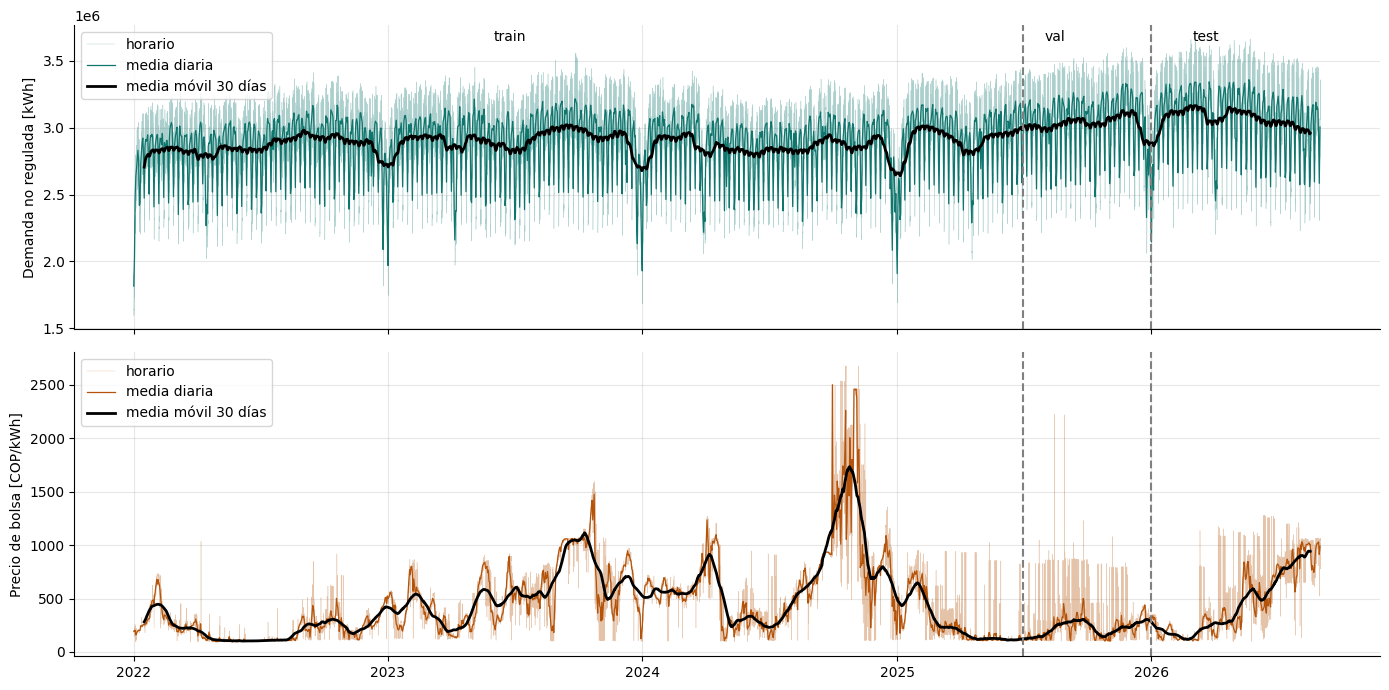

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, s, c in zip(axes, [D, P], ["demanda", "precio"]):
    ax.plot(s.index, s, lw=0.3, alpha=0.35, color=COLORES[c], label="horario")
    ax.plot(s.resample("D").mean(), lw=0.9, color=COLORES[c], label="media diaria")
    ax.plot(s.rolling(24 * 30, center=True).mean(), lw=2, color="k", label="media móvil 30 días")
    ax.axvline(pd.Timestamp(config.FIN_TRAIN), color="gray", ls="--")
    ax.axvline(pd.Timestamp(config.FIN_VAL), color="gray", ls="--")
    ax.set_ylabel(ETIQUETAS[s.name])
    ax.legend(loc="upper left")
ymax = axes[0].get_ylim()[1]
for x, t in [("2023-06-01", "train"), ("2025-08-01", "val"), ("2026-03-01", "test")]:
    axes[0].text(pd.Timestamp(x), ymax * 0.99, t, va="top")
fig.tight_layout()
guardar_figura(fig, "03_01_series_objetivo")
plt.show()

In [4]:
anual = h.groupby(h.index.year).mean()
anual["demanda_GWh_dia"] = anual.pop("demanda_kwh") * 24 / 1e6
anual["aportes_GWh_dia"] = anual.pop("aportes_kwh") / 1e6
anual["volumen_util_GWh"] = anual.pop("volumen_util_kwh") / 1e6
anual

,precio_bolsa_cop_kwh,precio_contrato_cop_kwh,demanda_GWh_dia,aportes_GWh_dia,volumen_util_GWh
fecha_hora,,,,,
2022,215.800,259.499,68.432,221.337,"13,150.252"
2023,558.121,277.516,69.751,190.243,"12,704.625"
2024,676.076,305.034,68.523,168.377,"8,972.027"
2025,240.268,289.903,71.347,248.615,"12,470.479"
2026,455.625,307.642,73.507,198.535,"12,392.228"


In [5]:
D.resample("QE").mean().to_frame("demanda_media_trimestral_kwh").tail(10)

,demanda_media_trimestral_kwh
fecha_hora,
2024-06-30,"2,841,862.762"
2024-09-30,"2,855,887.815"
2024-12-31,"2,852,935.816"
2025-03-31,"2,918,845.466"
2025-06-30,"2,906,015.024"
2025-09-30,"3,030,643.240"
2025-12-31,"3,033,839.788"
2026-03-31,"3,091,846.718"
2026-06-30,"3,072,800.218"


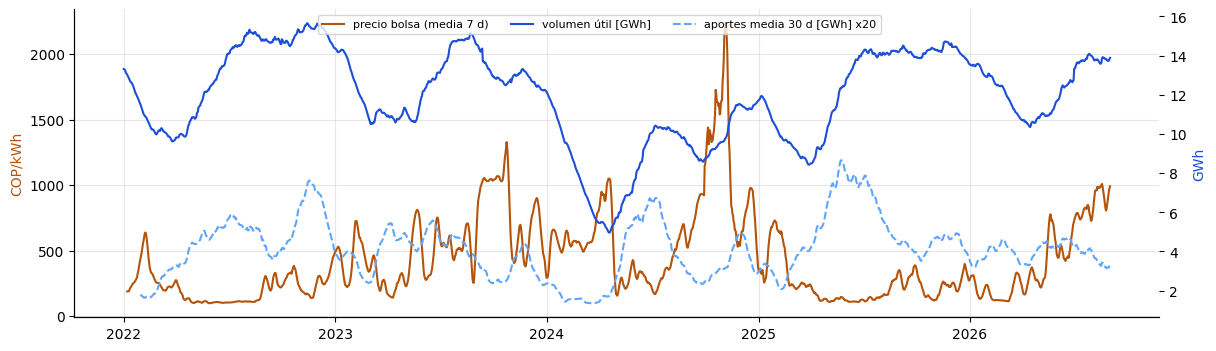

In [6]:
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(diario["precio_bolsa_cop_kwh"].rolling(7).mean(), color=COLORES["precio"], label="precio bolsa (media 7 d)")
ax1.set_ylabel("COP/kWh", color=COLORES["precio"])
ax2 = ax1.twinx()
ax2.plot(diario["volumen_util_kwh"] / 1e9, color="#1d4ed8", label="volumen útil [GWh]")
ax2.plot(diario["aportes_kwh"].rolling(30).mean() / 1e9 * 20, color="#60a5fa", ls="--", label="aportes media 30 d [GWh] x20")
ax2.set_ylabel("GWh", color="#1d4ed8")
ax2.grid(False)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.88), ncol=3, fontsize=8)
guardar_figura(fig, "03_02_hidrologia_precio")
plt.show()

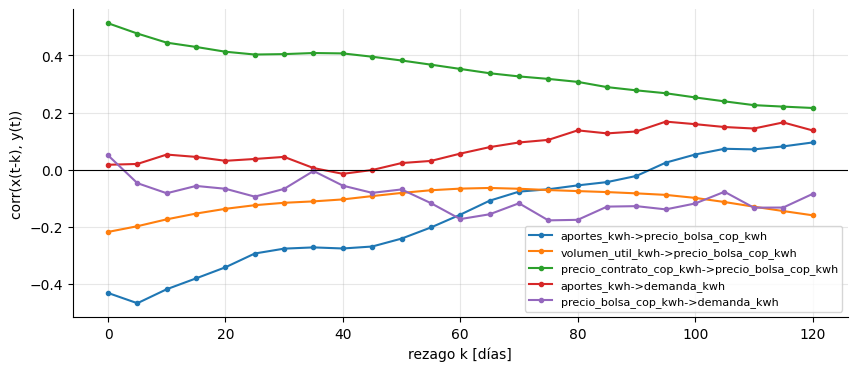

,aportes_kwh->precio_bolsa_cop_kwh,volumen_util_kwh->precio_bolsa_cop_kwh,precio_contrato_cop_kwh->precio_bolsa_cop_kwh,aportes_kwh->demanda_kwh,precio_bolsa_cop_kwh->demanda_kwh
0,-0.431,-0.218,0.512,0.017,0.050
15,-0.380,-0.153,0.429,0.045,-0.057
30,-0.276,-0.116,0.404,0.045,-0.067
60,-0.157,-0.066,0.352,0.056,-0.173
90,-0.022,-0.083,0.278,0.134,-0.127
120,0.095,-0.159,0.216,0.137,-0.085


In [7]:
rezagos = range(0, 121, 5)
cc = pd.concat([
    est.correlacion_cruzada(diario["aportes_kwh"], diario["precio_bolsa_cop_kwh"], rezagos),
    est.correlacion_cruzada(diario["volumen_util_kwh"], diario["precio_bolsa_cop_kwh"], rezagos),
    est.correlacion_cruzada(diario["precio_contrato_cop_kwh"], diario["precio_bolsa_cop_kwh"], rezagos),
    est.correlacion_cruzada(diario["aportes_kwh"], diario["demanda_kwh"], rezagos),
    est.correlacion_cruzada(diario["precio_bolsa_cop_kwh"], diario["demanda_kwh"], rezagos),
], axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
cc.plot(ax=ax, marker="o", ms=3)
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="rezago k [días]", ylabel="corr(x(t-k), y(t))")
ax.legend(fontsize=8)
guardar_figura(fig, "03_03_correlacion_cruzada")
plt.show()
cc.loc[[0, 15, 30, 60, 90, 120]]

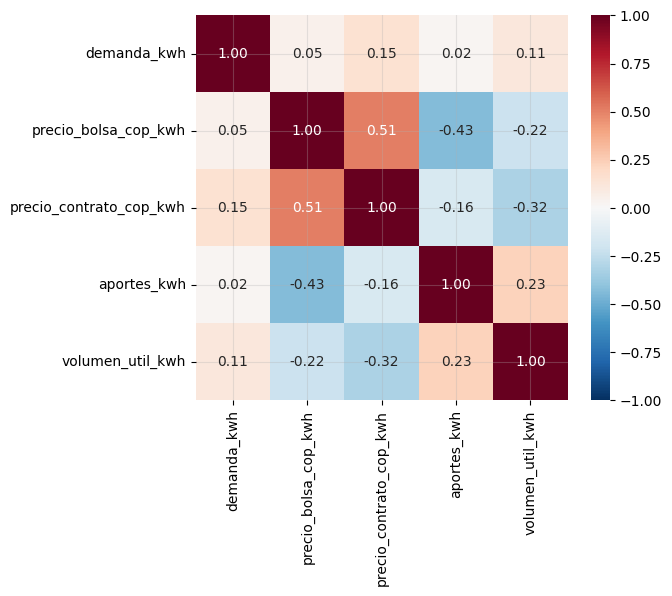

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(diario.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
guardar_figura(fig, "03_04_correlacion")
plt.show()

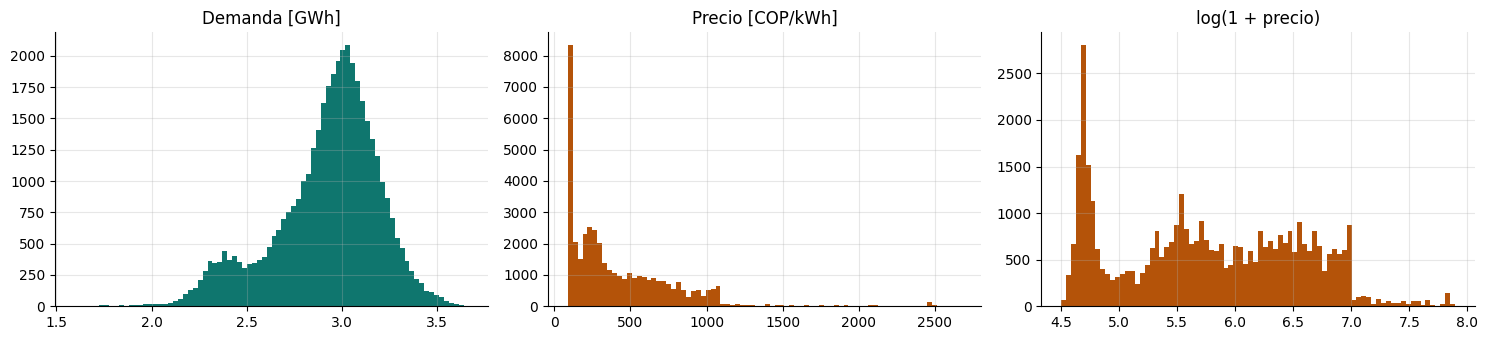

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(D / 1e6, bins=80, color=COLORES["demanda"])
axes[0].set(title="Demanda [GWh]")
axes[1].hist(P, bins=80, color=COLORES["precio"])
axes[1].set(title="Precio [COP/kWh]")
axes[2].hist(np.log1p(P), bins=80, color=COLORES["precio"])
axes[2].set(title="log(1 + precio)")
fig.tight_layout()
guardar_figura(fig, "03_05_distribuciones")
plt.show()

In [10]:
dist = est.resumen_distribucion(h)
dist.loc["log_precio_bolsa"] = est.resumen_distribucion(np.log1p(h[["precio_bolsa_cop_kwh"]])).iloc[0]
dist.loc["log_aportes"] = est.resumen_distribucion(np.log1p(h[["aportes_kwh"]])).iloc[0]
dist

,media,desv,cv_%,asimetria,curtosis
demanda_kwh,"2,920,096.489","277,380.289",9.499,-0.776,0.638
precio_bolsa_cop_kwh,427.429,355.878,83.260,1.988,6.448
precio_contrato_cop_kwh,286.517,20.097,7.014,0.011,-0.196
aportes_kwh,"205,892,547.797","91,795,762.761",44.584,0.966,1.342
volumen_util_kwh,"11,903,655,326.937","2,376,602,584.834",19.965,-0.652,-0.042
log_precio_bolsa,5.755,0.786,13.662,0.136,-1.019
log_aportes,19.043,0.458,2.406,-0.304,-0.124


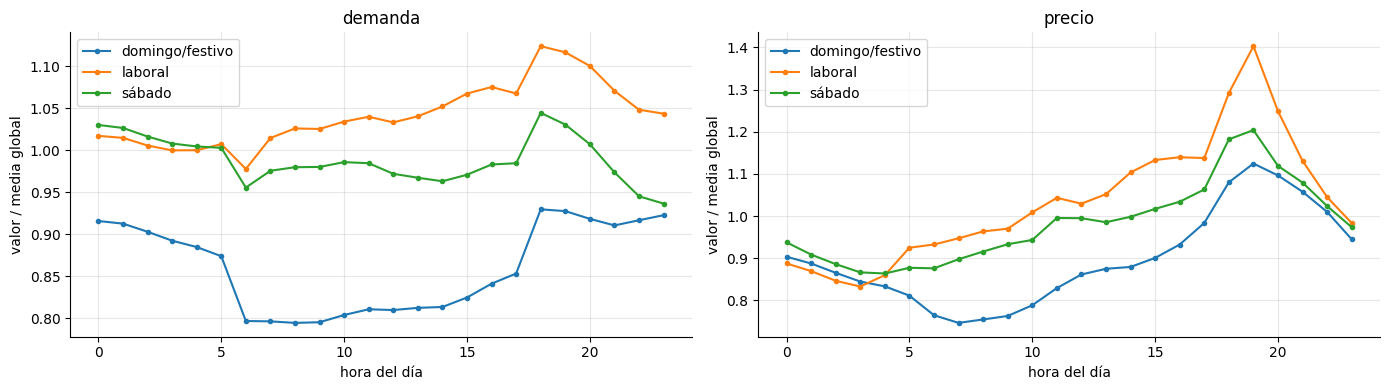

In [11]:
tipo_dia = np.select(
    [es_festivo(h.index), h.index.dayofweek == 6, h.index.dayofweek == 5],
    ["domingo/festivo", "domingo/festivo", "sábado"], "laboral",
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, s, c in zip(axes, [D, P], ["demanda", "precio"]):
    perfil = s.groupby([tipo_dia, s.index.hour]).mean().unstack(0) / s.mean()
    perfil.plot(ax=ax, marker=".")
    ax.set(xlabel="hora del día", ylabel="valor / media global", title=c)
fig.tight_layout()
guardar_figura(fig, "03_06_perfil_horario")
plt.show()

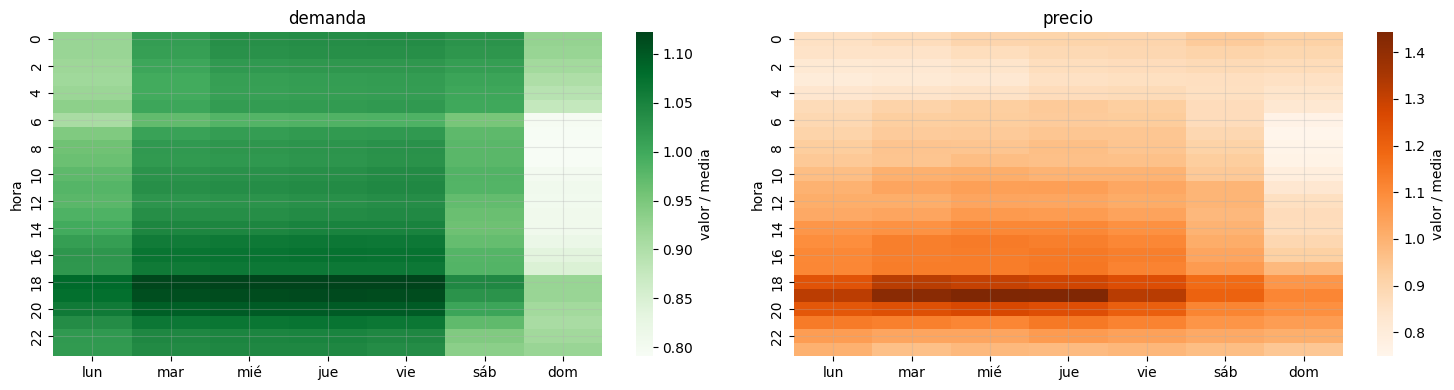

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
for ax, s, c, cmap in zip(axes, [D, P], ["demanda", "precio"], ["Greens", "Oranges"]):
    m = s.groupby([s.index.hour, s.index.dayofweek]).mean().unstack() / s.mean()
    m.columns = dias
    sns.heatmap(m, cmap=cmap, ax=ax, cbar_kws={"label": "valor / media"})
    ax.set(title=c, ylabel="hora")
fig.tight_layout()
guardar_figura(fig, "03_07_heatmap_hora_dia")
plt.show()

In [13]:
laboral = tipo_dia == "laboral"
efecto = pd.DataFrame({
    "demanda": D.groupby(tipo_dia).mean() / D[laboral].mean() - 1,
    "precio": P.groupby(tipo_dia).mean() / P[laboral].mean() - 1,
}) * 100
efecto

,demanda,precio
domingo/festivo,-17.385,-13.091
laboral,0.000,0.000
sábado,-5.099,-4.875


In [14]:
dd = D.resample("D").mean().to_frame("demanda")
dd["festivo"] = es_festivo(dd.index).to_numpy()
dd["dia"] = dd.index.dayofweek
dd["tipo"] = np.select(
    [dd["festivo"] & (dd["dia"] < 5), dd["dia"] == 6, dd["dia"] == 5],
    ["festivo entre semana", "domingo", "sábado"], "laboral",
)
base = dd.loc[dd["tipo"] == "laboral", "demanda"].mean()
efecto_festivos = dd.groupby("tipo")["demanda"].agg(["count", "mean"])
efecto_festivos["variacion_pct_vs_laboral"] = (efecto_festivos["mean"] / base - 1) * 100
efecto_festivos

,count,mean,variacion_pct_vs_laboral
tipo,,,
domingo,244,"2,510,289.125",-17.481
festivo entre semana,76,"2,530,725.073",-16.809
laboral,1140,"3,042,067.046",0.000
sábado,244,"2,881,321.030",-5.284


In [15]:
pd.Series({
    "festivos_total": int(dd["festivo"].sum()),
    "festivos_entre_semana": int((dd["festivo"] & (dd["dia"] < 5)).sum()),
    "festivos_en_lunes": int((dd["festivo"] & (dd["dia"] == 0)).sum()),
})

festivos_total           84
festivos_entre_semana    76
festivos_en_lunes        52
dtype: int64

In [16]:
error_naive_semanal = (dd["demanda"] - dd["demanda"].shift(7)).abs() / dd["demanda"] * 100
dd["festivo_ayer_o_hace_7"] = dd["festivo"].shift(7, fill_value=False)
pd.Series({
    "MAPE_laboral_normal": error_naive_semanal[(dd["tipo"] == "laboral") & ~dd["festivo_ayer_o_hace_7"]].mean(),
    "MAPE_festivo_entre_semana": error_naive_semanal[dd["tipo"] == "festivo entre semana"].mean(),
}, name="naive_m168_demanda_diaria")

MAPE_laboral_normal          2.408
MAPE_festivo_entre_semana   15.272
Name: naive_m168_demanda_diaria, dtype: float64

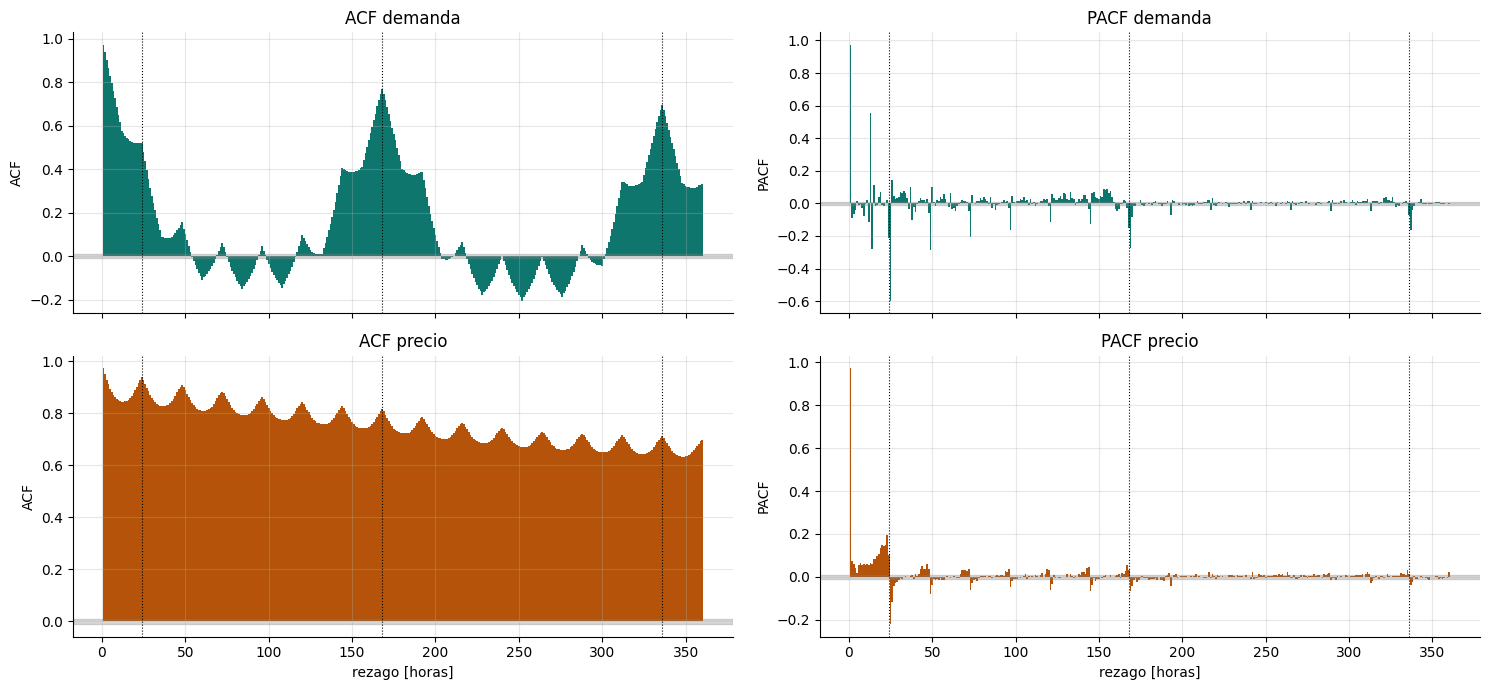

In [17]:
nl = 24 * 15
banda = est.banda_confianza(len(D))
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
for fila, (s, c) in enumerate([(D, "demanda"), (np.log1p(P), "precio")]):
    for col, (fn, nombre) in enumerate([(est.acf, "ACF"), (est.pacf, "PACF")]):
        ax = axes[fila, col]
        ax.bar(range(1, nl + 1), fn(s, nl)[1:], width=1.0, color=COLORES[c])
        ax.axhspan(-banda, banda, color="gray", alpha=0.3)
        for k in (24, 168, 336):
            ax.axvline(k, color="k", ls=":", lw=0.8)
        ax.set(ylabel=nombre, title=f"{nombre} {c}")
axes[1, 0].set_xlabel("rezago [horas]")
axes[1, 1].set_xlabel("rezago [horas]")
fig.tight_layout()
guardar_figura(fig, "03_08_acf_pacf")
plt.show()

In [18]:
rezagos_h = [1, 2, 24, 25, 48, 168, 169, 336]
pd.DataFrame({
    "acf_demanda": est.acf(D, 336)[rezagos_h],
    "pacf_demanda": est.pacf(D, 336)[rezagos_h],
    "acf_log_precio": est.acf(np.log1p(P), 336)[rezagos_h],
    "pacf_log_precio": est.pacf(np.log1p(P), 336)[rezagos_h],
}, index=rezagos_h).rename_axis("rezago_h")

,acf_demanda,pacf_demanda,acf_log_precio,pacf_log_precio
rezago_h,,,,
1,0.972,0.972,0.972,0.972
2,0.939,-0.090,0.949,0.073
24,0.523,-0.215,0.938,0.100
25,0.481,-0.597,0.927,-0.220
48,0.156,-0.060,0.908,0.037
168,0.770,-0.152,0.814,0.031
169,0.747,-0.277,0.807,-0.069
336,0.695,-0.069,0.711,0.013


In [19]:
pruebas = {
    "demanda": D,
    "demanda_dif24": D.diff(24).dropna(),
    "log_precio": np.log1p(P),
    "log_precio_dif24": np.log1p(P).diff(24).dropna(),
    "log_precio_diario": np.log1p(diario["precio_bolsa_cop_kwh"]),
}
pd.DataFrame({k: est.adf(v.to_numpy(), rezagos=48 if len(v) > 5000 else 14) for k, v in pruebas.items()}).T

,estadistico,critico_1%,critico_5%,critico_10%,estacionaria_5%
demanda,-28.022,-3.430,-2.860,-2.570,True
demanda_dif24,-25.247,-3.430,-2.860,-2.570,True
log_precio,-3.964,-3.430,-2.860,-2.570,True
log_precio_dif24,-29.088,-3.430,-2.860,-2.570,True
log_precio_diario,-3.339,-3.430,-2.860,-2.570,True


In [20]:
atip_p = est.atipicos_iqr(P, k=3)
atip_d = est.atipicos_iqr(D, k=3)
pd.Series({
    "horas_atipicas_precio": int(atip_p.sum()),
    "pct_precio": 100 * atip_p.mean(),
    "horas_atipicas_demanda": int(atip_d.sum()),
    "pct_demanda": 100 * atip_d.mean(),
})

horas_atipicas_precio    291.000
pct_precio                 0.712
horas_atipicas_demanda    39.000
pct_demanda                0.095
dtype: float64

In [21]:
atip_p.groupby(atip_p.index.date).sum().sort_values(ascending=False).head(8)

2024-09-30    24
2024-11-03    24
2024-11-02    24
2024-11-01    24
2024-10-31    24
2024-11-04    20
2024-10-19    19
2024-10-25    15
Name: precio_bolsa_cop_kwh, dtype: int64

In [22]:
pd.Series(tipo_dia[atip_d.to_numpy()]).value_counts()

domingo/festivo    39
Name: count, dtype: int64

In [23]:
def rango_rel(s):
    d = s.resample("D")
    return (d.max() - d.min()) / d.mean()

def semestre(idx):
    return idx.year.astype(str) + "-S" + ((idx.month > 6) + 1).astype(str)

r = rango_rel(P)
pico = P.resample("D").max() / P.resample("D").median()
tabla_sem = pd.DataFrame({
    "rango_intradia_pct": r.groupby(semestre(r.index)).mean() * 100,
    "max_sobre_mediana": pico.groupby(semestre(pico.index)).median(),
})
tabla_sem["particion"] = ["train"] * 7 + ["val", "test", "test"]
tabla_sem

,rango_intradia_pct,max_sobre_mediana,particion
fecha_hora,,,
2022-S1,30.481,1.060,train
2022-S2,45.509,1.052,train
2023-S1,45.770,1.081,train
2023-S2,53.174,1.080,train
2024-S1,44.806,1.101,train
2024-S2,61.373,1.132,train
2025-S1,107.334,1.316,train
2025-S2,176.701,2.278,val
2026-S1,92.973,1.423,test


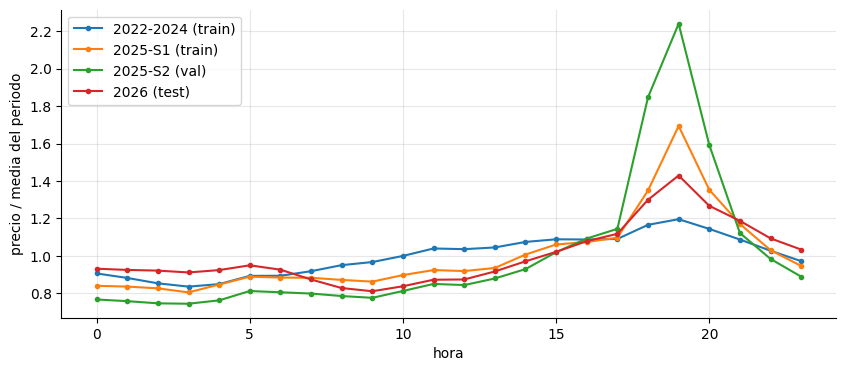

In [24]:
periodos = {
    "2022-2024 (train)": ("2022", "2024"),
    "2025-S1 (train)": ("2025-01", "2025-06"),
    "2025-S2 (val)": ("2025-07", "2025-12"),
    "2026 (test)": ("2026", "2026"),
}
fig, ax = plt.subplots(figsize=(10, 4))
for etiqueta, (ini, fin) in periodos.items():
    x = P[ini:fin]
    ax.plot((x.groupby(x.index.hour).mean() / x.mean()).values, marker=".", label=etiqueta)
ax.set(xlabel="hora", ylabel="precio / media del periodo")
ax.legend()
guardar_figura(fig, "03_09_cambio_perfil_precio")
plt.show()

In [25]:
desc = pd.DataFrame({
    "demanda": est.descomposicion_varianza_intradia(D),
    "precio": est.descomposicion_varianza_intradia(P),
    "log_precio": est.descomposicion_varianza_intradia(np.log1p(P)),
}).T[["pct_entre_dias", "pct_intra_dia"]]
desc["rango_intradia_medio_pct"] = [rango_rel(D).mean() * 100, rango_rel(P).mean() * 100, np.nan]
desc

,pct_entre_dias,pct_intra_dia,rango_intradia_medio_pct
demanda,78.625,21.375,15.158
precio,90.092,9.908,71.912
log_precio,89.844,10.156,NaN


In [26]:
particiones = {"train": ("2022", config.FIN_TRAIN), "val": (config.FIN_TRAIN, config.FIN_VAL), "test": (config.FIN_VAL, None)}
pd.DataFrame({
    p: {
        "demanda_pct_intra_dia": est.descomposicion_varianza_intradia(D[a:b])["pct_intra_dia"],
        "log_precio_pct_intra_dia": est.descomposicion_varianza_intradia(np.log1p(P[a:b]))["pct_intra_dia"],
    }
    for p, (a, b) in particiones.items()
}).T

,demanda_pct_intra_dia,log_precio_pct_intra_dia
train,21.787,8.488
val,25.717,45.315
test,27.184,9.959
